# Tennis Betting Efficiency - Exploratory Data Analysis

This notebook explores tennis match data and betting odds to analyze market efficiency.

In [12]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Add src directory to path
sys.path.append('../src')
from features import compute_implied_probability
from utils import check_missing_data, safe_has, plot_calibration
from models import calculate_calibration

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load Data

Load tennis match data from CSV files in the `data/raw/` directory.

In [13]:
# Load data from data/raw/ directory
data_dir = Path('../data/raw')
xlsx_files = list(data_dir.glob('*.xlsx'))

if len(xlsx_files) == 0:
    print("No XLSX files found in data/raw/")
    print("Please add tennis match data XLSX files to the data/raw/ directory.")
    print("\nExpected columns might include:")
    print("- player1, player2: Player names")
    print("- player1_odds, player2_odds: Betting odds")
    print("- winner: Match winner (1 or 2)")
    print("- surface: Court surface (Hard, Clay, Grass)")
    print("- player1_rank, player2_rank: Player rankings")
    
    # Create sample data for demonstration
    print("\nCreating sample data for demonstration...")
    np.random.seed(42)
    n_matches = 100
    
    data = pd.DataFrame({
        'player1': [f'Player_A{i%20}' for i in range(n_matches)],
        'player2': [f'Player_B{i%20}' for i in range(n_matches)],
        'player1_odds': np.random.uniform(1.3, 3.5, n_matches).round(2),
        'player2_odds': np.random.uniform(1.3, 3.5, n_matches).round(2),
        'winner': np.random.choice([1, 2], n_matches),
        'surface': np.random.choice(['Hard', 'Clay', 'Grass'], n_matches),
        'player1_rank': np.random.randint(1, 100, n_matches),
        'player2_rank': np.random.randint(1, 100, n_matches),
        'tournament': np.random.choice(['Grand Slam', 'Masters', 'ATP 250'], n_matches)
    })
    
    # Introduce some missing values
    mask = np.random.random(n_matches) < 0.1
    data.loc[mask, 'player1_rank'] = np.nan
    data.loc[mask, 'player2_rank'] = np.nan
else:
    print(f"Found {len(xlsx_files)} XLSX file(s):")
    for f in xlsx_files:
        print(f"  - {f.name}")

    # Load the XLSX files
    datas = [pd.read_excel(f) for f in xlsx_files]
    data = pd.concat(datas, ignore_index=True)
    print(f"\nLoaded and combined {len(datas)} yearly files.")

print(f"\nDataset shape: {data.shape}")
print(f"\nFirst few rows:")
data.head()

Found 10 XLSX file(s):
  - 2021.xlsx
  - 2017.xlsx
  - 2016.xlsx
  - 2020.xlsx
  - 2024.xlsx
  - 2019.xlsx
  - 2023.xlsx
  - 2015.xlsx
  - 2022.xlsx
  - 2018.xlsx


/opt/anaconda3/envs/py39-statsmodels/lib/python3.9/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
/opt/anaconda3/envs/py39-statsmodels/lib/python3.9/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():



Loaded and combined 10 yearly files.

Dataset shape: (24930, 40)

First few rows:


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,...,PSW,PSL,MaxW,MaxL,AvgW,AvgL,EXW,EXL,LBW,LBL
0,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Basilashvili N.,...,1.61,2.44,1.67,2.56,1.56,2.42,NaN,NaN,NaN,NaN
1,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Celikbilek A.,...,2.63,1.54,2.70,1.55,2.57,1.50,NaN,NaN,NaN,NaN
2,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Ruusuvuori E.,...,1.56,2.58,1.63,3.03,1.52,2.53,NaN,NaN,NaN,NaN
3,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Bublik A.,...,1.81,2.09,1.87,2.30,1.72,2.11,NaN,NaN,NaN,NaN
4,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Goffin D.,...,1.46,2.92,1.50,3.00,1.44,2.78,NaN,NaN,NaN,NaN


## 2. Data Cleaning

Clean and prepare the data for analysis.

In [14]:
# Display basic information
print("Dataset Information:")
print(data.info())

# Check for duplicate rows
n_duplicates = data.duplicated().sum()
print(f"\nNumber of duplicate rows: {n_duplicates}")

if n_duplicates > 0:
    data = data.drop_duplicates()
    print(f"Removed {n_duplicates} duplicate rows")
    
# Sort data by date
if 'Date' in data.columns:
    data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
    data = data.sort_values(by='Date', ascending=False).reset_index(drop=True)
    print("Data sorted by date.")

# Map: short code -> (winner_odds_col, loser_odds_col)
BOOKS = {
    'B365': ('B365W','B365L'),   # Bet365
    'PS':   ('PSW','PSL'),       # Pinnacle Sports
    'MAX':  ('MaxW','MaxL'),     # Maximum odds across bookmakers
    'AVG':  ('AvgW','AvgL'),     # Average odds across bookmakers
}

# check which bookmakers have non-missing odds
availability = {}
for code, (wcol, lcol) in BOOKS.items():
    if wcol in data.columns and lcol in data.columns:
        count = data[[wcol, lcol]].dropna().shape[0]
        availability[code] = count

availability = pd.Series(availability).sort_values(ascending=False)
print("\nBookmaker odds coverage (rows with both winner & loser odds):")
print(availability)

# Drop bookmaker columns with more than 30% missing data
drop_cols = ['EXW', 'EXL', 'LBW', 'LBL', 'BFEW', 'BFEL']
data = data.drop(columns=[col for col in drop_cols if col in data.columns])
print(f"\nDropped bookmaker columns with >30% missing data: {drop_cols}")

print(f"\nCleaned dataset shape: {data.shape}")

print(data.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24930 entries, 0 to 24929
Data columns (total 40 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ATP         24930 non-null  int64         
 1   Location    24930 non-null  object        
 2   Tournament  24930 non-null  object        
 3   Date        24930 non-null  datetime64[ns]
 4   Series      24930 non-null  object        
 5   Court       24930 non-null  object        
 6   Surface     24930 non-null  object        
 7   Round       24930 non-null  object        
 8   Best of     24915 non-null  float64       
 9   Winner      24930 non-null  object        
 10  Loser       24930 non-null  object        
 11  WRank       24919 non-null  float64       
 12  LRank       24875 non-null  float64       
 13  WPts        24920 non-null  float64       
 14  LPts        24875 non-null  float64       
 15  W1          24770 non-null  float64       
 16  L

## 3. Analyze Missing Data

Identify and visualize missing data patterns.

Missing Data Summary:
 column  missing_count  missing_pct
     L5          23979        96.19
     W5          23979        96.19
     L4          22380        89.77
     W4          22380        89.77
     W3          12890        51.70
     L3          12890        51.70
     W2            348         1.40
     L2            348         1.40
  Lsets            163         0.65
     W1            160         0.64
  Wsets            160         0.64
     L1            157         0.63
    PSW            111         0.45
    PSL            111         0.45
  B365W             90         0.36
  B365L             89         0.36
   LPts             55         0.22
  LRank             55         0.22
   MaxW             24         0.10
   MaxL             24         0.10
   AvgW             24         0.10
   AvgL             24         0.10
Best of             15         0.06
  WRank             11         0.04
   WPts             10         0.04


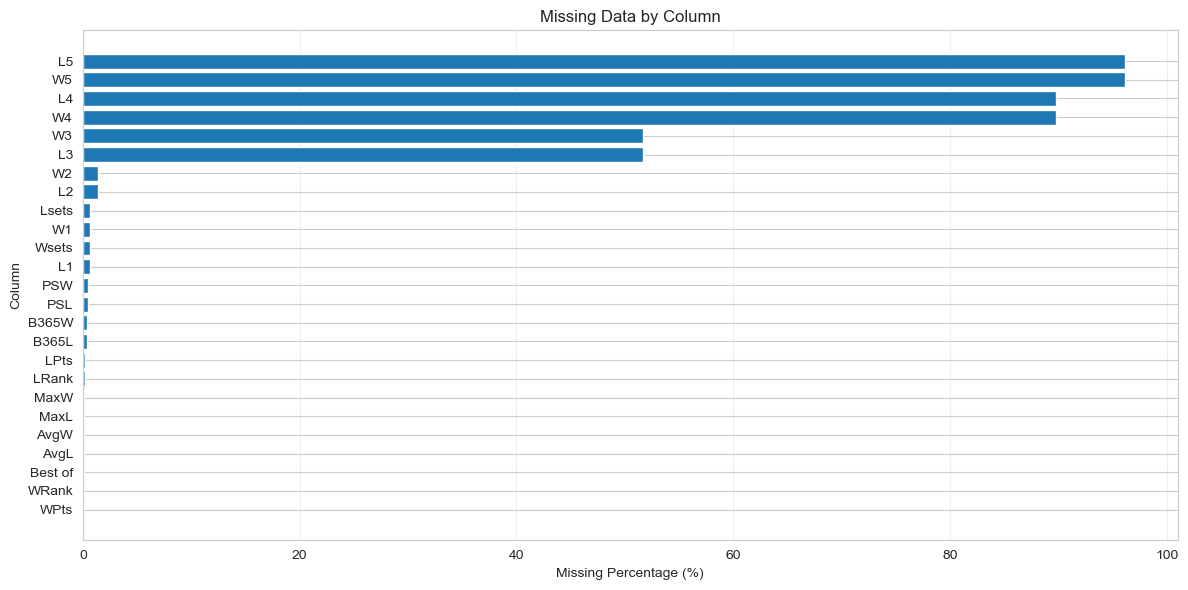

Dropping 66 rows missing all main bookmaker odds.

Overall data completeness: 86.62%


In [15]:
# Check for missing data
missing_data = check_missing_data(data)

if len(missing_data) > 0:
    print("Missing Data Summary:")
    print(missing_data.to_string(index=False))
    
    # Visualize missing data
    fig, ax = plt.subplots(figsize=(12, 6))
    missing_data_sorted = missing_data.sort_values('missing_pct', ascending=True)
    ax.barh(missing_data_sorted['column'], missing_data_sorted['missing_pct'])
    ax.set_xlabel('Missing Percentage (%)')
    ax.set_ylabel('Column')
    ax.set_title('Missing Data by Column')
    ax.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print("No missing data found!")

# Drop rows where both B365 and PS are missing
mask_missing = data[['B365W','B365L','PSW','PSL']].isna().all(axis=1)
print(f"Dropping {mask_missing.sum()} rows missing all main bookmaker odds.")
data = data[~mask_missing].reset_index(drop=True)

# Show overall completeness
total_values = data.shape[0] * data.shape[1]
missing_values = data.isnull().sum().sum()
completeness = (1 - missing_values / total_values) * 100
print(f"\nOverall data completeness: {completeness:.2f}%")

## 4. Compute Implied Probabilities from Odds

Convert betting odds to implied probabilities.

PSW      24819
PSL      24819
B365W    24840
B365L    24841
AvgW     24863
AvgL     24863
MaxW     24863
MaxL     24863
dtype: int64

Rows with any main odds present (W & L):
24864
[PS] Average overround: 1.0252  -> avg margin (vig): 2.52%


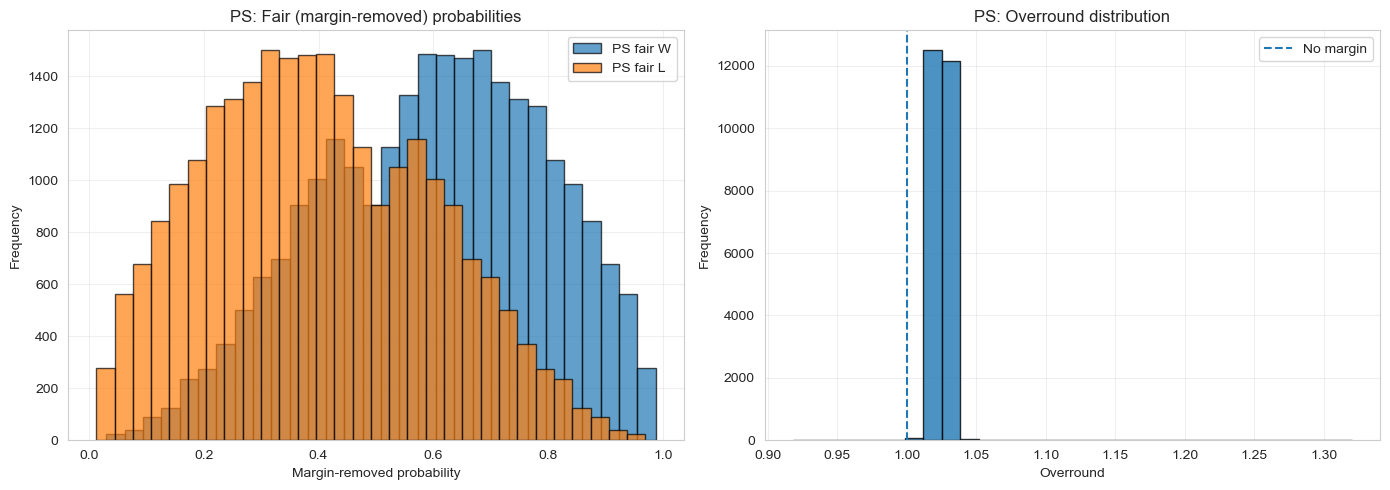


Implied Probabilities Computed (adapter to generic columns):

Average overround: 1.0252
This indicates an average bookmaker margin of 2.52%

Sample of odds and implied probabilities:
   player1_odds  player1_implied_prob  player2_odds  player2_implied_prob  \
0          1.17              0.854701          5.24              0.190840   
1          2.85              0.350877          1.48              0.675676   
2          1.06              0.943396         12.48              0.080128   
3          2.02              0.495050          1.87              0.534759   
4          2.59              0.386100          1.56              0.641026   
5          1.19              0.840336          5.29              0.189036   
6          3.09              0.323625          1.42              0.704225   
7          1.18              0.847458          5.56              0.179856   
8          1.58              0.632911          2.52              0.396825   
9          1.18              0.847458         

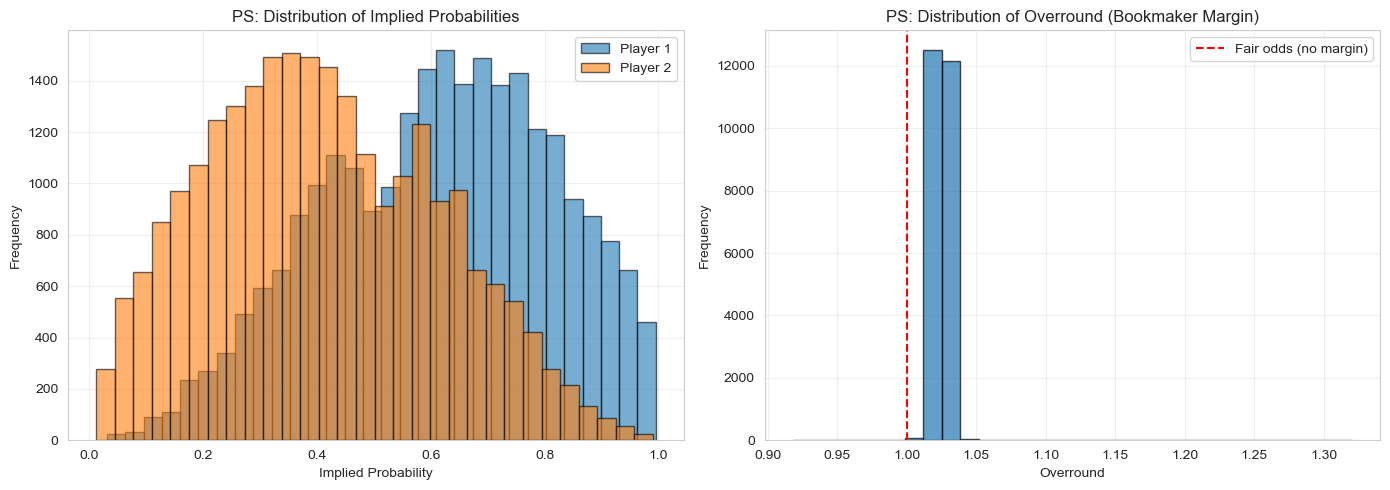

In [16]:
# Compute implied probs, overround, vig, and margin-removed ("fair") probs

print(data[['PSW','PSL','B365W','B365L','AvgW','AvgL','MaxW','MaxL']].notna().sum())
print("\nRows with any main odds present (W & L):")
print( (data[['PSW','PSL']].notna().all(axis=1) |
        data[['B365W','B365L']].notna().all(axis=1) |
        data[['AvgW','AvgL']].notna().all(axis=1) |
        data[['MaxW','MaxL']].notna().all(axis=1) ).sum() )

# Coerce to numeric; set bad values (<=1 or nonfinite) to NaN
for _, (wcol, lcol) in BOOKS.items():
    if wcol in data.columns:
        data[wcol] = pd.to_numeric(data[wcol], errors='coerce')
        data.loc[~np.isfinite(data[wcol]) | (data[wcol] <= 1), wcol] = np.nan
    if lcol in data.columns:
        data[lcol] = pd.to_numeric(data[lcol], errors='coerce')
        data.loc[~np.isfinite(data[lcol]) | (data[lcol] <= 1), lcol] = np.nan
        
made_any = False
for code, (wcol, lcol) in BOOKS.items():
    if safe_has(data, wcol, lcol):
        # raw implied probs from decimal odds
        data[f'{code}_W_ip'] = compute_implied_probability(data[wcol])
        data[f'{code}_L_ip'] = compute_implied_probability(data[lcol])

        # overround (book percentage) and vigorish
        data[f'{code}_overround'] = data[f'{code}_W_ip'] + data[f'{code}_L_ip']
        data[f'{code}_vig'] = data[f'{code}_overround'] - 1.0
        
        # margin-removed ("fair") probabilities (normalize to sum to 1)
        data[f'{code}_W_fair'] = data[f'{code}_W_ip'] / data[f'{code}_overround']
        data[f'{code}_L_fair'] = data[f'{code}_L_ip'] / data[f'{code}_overround']
        
        made_any = True

if not made_any:
    raise ValueError("No known bookmaker odds columns were found. Check column names.")

# Pick a reference bookmaker to summarize (falls back to any available)
ref = None
for c in ['PS','B365','AVG','MAX']:
    if f'{c}_overround' in data.columns:
        ref = c; break

if ref:
    avg_overround = data[f'{ref}_overround'].dropna().mean()
    print(f"[{ref}] Average overround: {avg_overround:.4f}  -> avg margin (vig): {(avg_overround-1)*100:.2f}%")
else:
    print("No overround columns to summarize.")
    
plot_code = ref  # or set manually, e.g. 'PS' or 'B365'
if plot_code:
    fig, axes = plt.subplots(1, 2, figsize=(14,5))

    axes[0].hist(data[f'{plot_code}_W_fair'].dropna(), bins=30, alpha=0.7, edgecolor='black', label=f'{plot_code} fair W')
    axes[0].hist(data[f'{plot_code}_L_fair'].dropna(), bins=30, alpha=0.7, edgecolor='black', label=f'{plot_code} fair L')
    axes[0].set_xlabel('Margin-removed probability')
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'{plot_code}: Fair (margin-removed) probabilities')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].hist(data[f'{plot_code}_overround'].dropna(), bins=30, edgecolor='black', alpha=0.8)
    axes[1].axvline(1.0, linestyle='--', label='No margin')
    axes[1].set_xlabel('Overround')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'{plot_code}: Overround distribution')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    
# --------------------------------------------------------------------
# "player1_/player2_" flow for one bookmaker
# --------------------------------------------------------------------

# choose which bookmaker to mirror (must exist in BOOKS and in your data)
book = ref  # or set explicitly, e.g. 'PS' or 'B365'

if book and all(k in data.columns for k in BOOKS[book]):
    # map that bookmaker's odds to generic columns
    data['player1_odds'] = data[BOOKS[book][0]]
    data['player2_odds'] = data[BOOKS[book][1]]

    # reuse already-computed implied probs and overround
    data['player1_implied_prob'] = data[f'{book}_W_ip']
    data['player2_implied_prob'] = data[f'{book}_L_ip']
    data['overround'] = data[f'{book}_overround']

    # print summary exactly like the original cell
    print("\nImplied Probabilities Computed (adapter to generic columns):")
    print(f"\nAverage overround: {data['overround'].mean():.4f}")
    print(f"This indicates an average bookmaker margin of {(data['overround'].mean() - 1) * 100:.2f}%")

    # sample table
    display_cols = ['player1_odds','player1_implied_prob','player2_odds','player2_implied_prob','overround']
    print("\nSample of odds and implied probabilities:")
    print(data[display_cols].head(10))

    # plots: raw implied probs + overround, matching the original pattern
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(data['player1_implied_prob'].dropna(), bins=30, alpha=0.6, label='Player 1', edgecolor='black')
    axes[0].hist(data['player2_implied_prob'].dropna(), bins=30, alpha=0.6, label='Player 2', edgecolor='black')
    axes[0].set_xlabel('Implied Probability')
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'{book}: Distribution of Implied Probabilities')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].hist(data['overround'].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[1].axvline(x=1.0, color='red', linestyle='--', label='Fair odds (no margin)')
    axes[1].set_xlabel('Overround')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'{book}: Distribution of Overround (Bookmaker Margin)')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("\nAdapter skipped: chosen bookmaker not present or columns missing.")

### Bookmaker Summary Table

In [17]:
rows = []
for code, (wcol, lcol) in BOOKS.items():
    ocol = f'{code}_overround'
    vcol = f'{code}_vig'
    if ocol in data.columns and vcol in data.columns:
        rows.append({
            'Bookmaker': code,
            'Average Overround': data[ocol].mean(skipna=True),
            'Average Vigorish': data[vcol].mean(skipna=True),
            'Count': data[[ocol, vcol]].dropna().shape[0]
        })

if rows:
    book_summary = pd.DataFrame(rows).sort_values('Average Overround')
    print("\nBookmaker summary (lower overround/vig is tighter pricing):")
    print(book_summary)


Bookmaker summary (lower overround/vig is tighter pricing):
  Bookmaker  Average Overround  Average Vigorish  Count
2       MAX           0.999900         -0.000100  24863
1        PS           1.025213          0.025213  24815
3       AVG           1.055065          0.055065  24862
0      B365           1.059931          0.059931  24823


### Arbitrage Flag Using MaxW/MaxL(two-outcome)

In [18]:
if safe_has(data, 'MaxW','MaxL'):
    data['arb_flag'] = (1/data['MaxW'] + 1/data['MaxL']) < 1.0
    arb_rate = data['arb_flag'].mean()
    print(f"\nArbitrage (Max) rate: {arb_rate*100:.2f}% of matches")

    # example breakdowns
    if 'Surface' in data.columns:
        by_surface = (data.groupby('Surface')['arb_flag'].mean()*100).round(2).sort_values(ascending=False)
        print("\nArbitrage rate by Surface (%):")
        print(by_surface)
    if 'Series' in data.columns:
        by_series = (data.groupby('Series')['arb_flag'].mean()*100).round(2).sort_values(ascending=False)
        print("\nArbitrage rate by Series (%):")
        print(by_series)


Arbitrage (Max) rate: 41.80% of matches

Arbitrage rate by Surface (%):
Surface
Grass    43.67
Clay     42.16
Hard     41.23
Name: arb_flag, dtype: float64

Arbitrage rate by Series (%):
Series
Masters Cup     64.00
ATP250          43.27
Grand Slam      43.05
ATP500          39.25
Masters 1000    39.04
Name: arb_flag, dtype: float64


## 5. Player Rank and Surface Distributions

Analyze the distribution of player rankings and match surfaces.

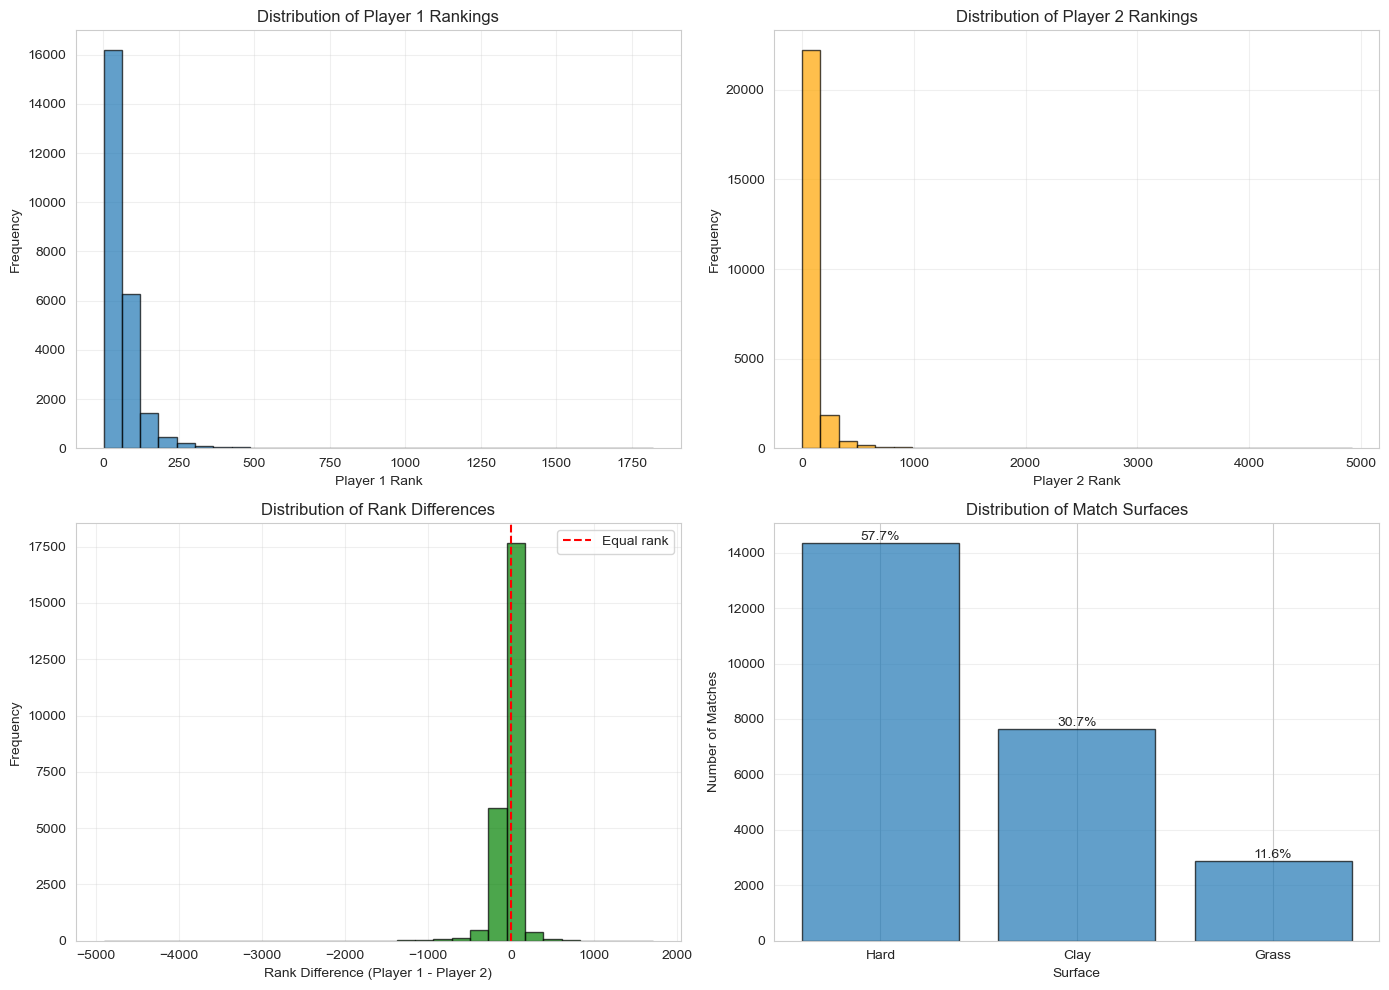


Rank Statistics:
Player 1 Rank - Mean: 59.2, Median: 42.0
Player 2 Rank - Mean: 89.9, Median: 63.0

Surface Distribution:
Hard     14357
Clay      7633
Grass     2874
Name: Surface, dtype: int64


In [19]:
# Analyze rank distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Player 1 rank distribution
if 'WRank' in data.columns:
    axes[0, 0].hist(data['WRank'].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[0, 0].set_xlabel('Player 1 Rank')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].set_title('Distribution of Player 1 Rankings')
    axes[0, 0].grid(True, alpha=0.3)

# Player 2 rank distribution
if 'LRank' in data.columns:
    axes[0, 1].hist(data['LRank'].dropna(), bins=30, edgecolor='black', alpha=0.7, color='orange')
    axes[0, 1].set_xlabel('Player 2 Rank')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title('Distribution of Player 2 Rankings')
    axes[0, 1].grid(True, alpha=0.3)

# Rank difference
if 'WRank' in data.columns and 'LRank' in data.columns:
    rank_diff = (data['WRank'] - data['LRank']).dropna()
    axes[1, 0].hist(rank_diff, bins=30, edgecolor='black', alpha=0.7, color='green')
    axes[1, 0].axvline(x=0, color='red', linestyle='--', label='Equal rank')
    axes[1, 0].set_xlabel('Rank Difference (Player 1 - Player 2)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Distribution of Rank Differences')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

# Surface distribution
if 'Surface' in data.columns:
    surface_counts = data['Surface'].value_counts()
    axes[1, 1].bar(surface_counts.index, surface_counts.values, edgecolor='black', alpha=0.7)
    axes[1, 1].set_xlabel('Surface')
    axes[1, 1].set_ylabel('Number of Matches')
    axes[1, 1].set_title('Distribution of Match Surfaces')
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    
    # Add percentage labels
    total = surface_counts.sum()
    for i, (surface, count) in enumerate(surface_counts.items()):
        pct = count / total * 100
        axes[1, 1].text(i, count, f'{pct:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nRank Statistics:")
if 'WRank' in data.columns:
    print(f"Player 1 Rank - Mean: {data['WRank'].mean():.1f}, Median: {data['WRank'].median():.1f}")
if 'LRank' in data.columns:
    print(f"Player 2 Rank - Mean: {data['LRank'].mean():.1f}, Median: {data['LRank'].median():.1f}")

if 'Surface' in data.columns:
    print("\nSurface Distribution:")
    print(data['Surface'].value_counts())

In [20]:
# ---------- Split master table into clean, purpose-built datasets ----------
# 0) Where to save
out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)

def cols_present(df, cols):
    """Return only the columns that actually exist to avoid KeyErrors."""
    return [c for c in cols if c in df.columns]

# 1) Core dataset for modeling (compact, essential fields)
core_cols = [
    # Match metadata
    'ATP','Location','Tournament','Date','Series','Court','Surface','Round','Best of',
    # Players
    'Winner','Loser',
    # Ranking/context
    'WRank','LRank','WPts','LPts','Wsets','Lsets',
    # Primary bookmaker(s): raw + derived (keep at most 1–2 books)
    'B365W','B365L','PSW','PSL',
    'B365_W_ip','B365_L_ip','B365_overround','B365_W_fair','B365_L_fair',
    'PS_W_ip','PS_L_ip','PS_overround','PS_W_fair','PS_L_fair',
    # Generic modeling columns
    'player1_odds','player2_odds','player1_implied_prob','player2_implied_prob','overround',
    # Flags
    'arb_flag'
]
core = data[cols_present(data, core_cols)].copy()
core_path = out_dir / "match_core.xlsx"
core.to_excel(core_path, index=False)

# 2) Full odds panel (keep all books + derived for bookmaker research)
odds_cols = [
    # Raw odds
    'B365W','B365L','PSW','PSL','MaxW','MaxL','AvgW','AvgL',
    # Derived: implied prob / overround / fair probs / vig
    'B365_W_ip','B365_L_ip','B365_overround','B365_vig','B365_W_fair','B365_L_fair',
    'PS_W_ip','PS_L_ip','PS_overround','PS_vig','PS_W_fair','PS_L_fair',
    'MAX_W_ip','MAX_L_ip','MAX_overround','MAX_vig','MAX_W_fair','MAX_L_fair',
    'AVG_W_ip','AVG_L_ip','AVG_overround','AVG_vig','AVG_W_fair','AVG_L_fair',
    # Generic combined view
    'player1_odds','player2_odds','player1_implied_prob','player2_implied_prob','overround',
]
odds_full = data[cols_present(data, odds_cols)].copy()
odds_path = out_dir / "odds_full.xlsx"
odds_full.to_excel(odds_path, index=False)

# 3) Detailed set-by-set scores (useful for later progression/volatility work)
sets_cols = ['Date','Tournament','Round','Surface','Winner','Loser',
             'W1','L1','W2','L2','W3','L3','W4','L4','W5','L5','Wsets','Lsets','Comment']
sets_detailed = data[cols_present(data, sets_cols)].copy()
sets_path = out_dir / "sets_detailed.xlsx"
sets_detailed.to_excel(sets_path, index=False)

# (Optional) lightweight archive of everything else for traceability
archive_cols = [c for c in data.columns if c not in set(core.columns) | set(odds_full.columns) | set(sets_detailed.columns)]
archive = data[archive_cols].copy()
archive_path = out_dir / "aux_archive.xlsx"
archive.to_excel(archive_path, index=False)

# Pretty summary
print("Saved:")
print(f"  - Core modeling dataset    : {core.shape}  -> {core_path}")
print(f"  - Full odds panel          : {odds_full.shape}  -> {odds_path}")
print(f"  - Set-by-set details       : {sets_detailed.shape}  -> {sets_path}")
print(f"  - Aux/leftover columns     : {archive.shape}  -> {archive_path}")

# (Optional) quick sanity checks
def quick_nulls(df, name):
    miss = df.isna().mean().sort_values(ascending=False)
    print(f"\nTop 10 missing columns in {name}:")
    print((miss.head(10)*100).round(2).astype(str) + '%')

quick_nulls(core, "core")
quick_nulls(odds_full, "odds_full")
quick_nulls(sets_detailed, "sets_detailed")

Saved:
  - Core modeling dataset    : (24864, 37)  -> ../data/processed/match_core.xlsx
  - Full odds panel          : (24864, 37)  -> ../data/processed/odds_full.xlsx
  - Set-by-set details       : (24864, 19)  -> ../data/processed/sets_detailed.xlsx
  - Aux/leftover columns     : (24864, 0)  -> ../data/processed/aux_archive.xlsx

Top 10 missing columns in core:
Lsets                   0.63%
Wsets                   0.62%
LRank                   0.22%
LPts                    0.22%
overround                0.2%
player1_implied_prob     0.2%
player1_odds             0.2%
PS_L_fair                0.2%
PS_W_ip                  0.2%
PS_W_fair                0.2%
dtype: object

Top 10 missing columns in odds_full:
PS_W_fair                0.2%
PS_W_ip                  0.2%
player1_implied_prob     0.2%
player1_odds             0.2%
PS_L_fair                0.2%
PS_vig                   0.2%
PS_overround             0.2%
overround                0.2%
PSW                      0.2%
PSL         

## 6. Market Calibration Analysis

Assess how well betting markets predict actual outcomes through calibration plots.

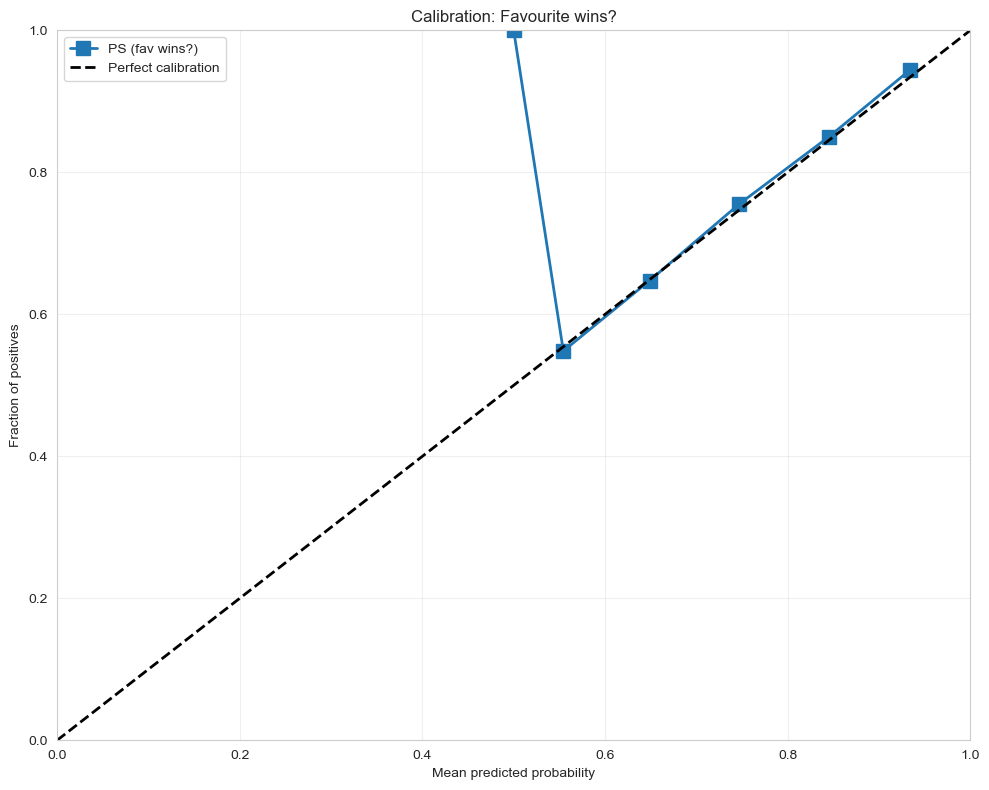

Calibration Metrics (favourite wins?)
  Log Loss : 0.5811
  Brier    : 0.1993
  AUC      : 0.6621

Calibration by surface (favourite wins?):
  Clay: LogLoss=0.5877 Brier=0.2022
  Grass: LogLoss=0.5682 Brier=0.1942
  Hard: LogLoss=0.5803 Brier=0.1988

Winner-probability sharpness (PS):
  Log Loss : 0.5811
  Brier    : 0.1993


In [21]:
# --- Calibration: favourite-wins (recommended) --------------------------------
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

# choose bookmaker to evaluate (use your selected ref or set explicitly)
book = ref if ref in ['PS','B365','AVG','MAX'] else 'PS'

needed = [f'{book}_W_fair', f'{book}_L_fair']
if all(col in data.columns for col in needed):
    # favourite's predicted win prob (pre-match): max of the two fair probs
    p_fav = np.maximum(data[f'{book}_W_fair'], data[f'{book}_L_fair'])
    # did the favourite actually win? winner is "W", so favourite-won iff W_fair >= L_fair
    y_true_fav = (data[f'{book}_W_fair'] >= data[f'{book}_L_fair']).astype(int)

    # keep only finite rows
    mask = np.isfinite(p_fav) & np.isfinite(y_true_fav)
    y_pred = p_fav[mask].clip(1e-15, 1-1e-15)
    y_true = y_true_fav[mask]

    if y_pred.size >= 10 and y_true.nunique() == 2:
        # calibration curve
        frac_pos, mean_pred = calibration_curve(y_true, y_pred, n_bins=min(10, max(3, int(y_pred.size**0.5))))
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.plot(mean_pred, frac_pos, 's-', markersize=10, linewidth=2, label=f'{book} (fav wins?)')
        ax.plot([0,1],[0,1],'k--', linewidth=2, label='Perfect calibration')
        ax.set_xlabel('Mean predicted probability')
        ax.set_ylabel('Fraction of positives')
        ax.set_title('Calibration: Favourite wins?')
        ax.legend(); ax.grid(True, alpha=0.3); ax.set_xlim([0,1]); ax.set_ylim([0,1])
        plt.tight_layout(); plt.show()

        # metrics
        print("Calibration Metrics (favourite wins?)")
        print(f"  Log Loss : {log_loss(y_true, y_pred):.4f}")
        print(f"  Brier    : {brier_score_loss(y_true, y_pred):.4f}")
        print(f"  AUC      : {roc_auc_score(y_true, y_pred):.4f}")

        # optional: by surface (handle 'Surface' or 'surface')
        surf_col = 'Surface' if 'Surface' in data.columns else ('surface' if 'surface' in data.columns else None)
        if surf_col:
            print("\nCalibration by surface (favourite wins?):")
            for s, sub in data.loc[mask].assign(y_true=y_true, y_pred=y_pred).groupby(data.loc[mask, surf_col]):
                if sub.shape[0] >= 30 and sub['y_true'].nunique() == 2:
                    print(f"  {s}: LogLoss={log_loss(sub['y_true'], sub['y_pred']):.4f} "
                          f"Brier={brier_score_loss(sub['y_true'], sub['y_pred']):.4f}")
    else:
        print("Not enough mixed labels for favourite-wins calibration, or too few rows.")
else:
    print(f"Missing columns for {book} fair probs: {needed}")

# --- Calibration: winner-probability sharpness (all positives) ----------------
# This evaluates how sharp the assigned probability to the actual outcome (winner) is.
if f'{book}_W_fair' in data.columns:
    p_win = data[f'{book}_W_fair']
    p_win = p_win[np.isfinite(p_win)].clip(1e-15, 1-1e-15)
    if p_win.size >= 10:
        y_true_all1 = np.ones(len(p_win), dtype=int)
        ll = log_loss(y_true_all1, p_win, labels=[0,1])  # labels avoids the single-class error
        bs = brier_score_loss(y_true_all1, p_win)
        print(f"\nWinner-probability sharpness ({book}):")
        print(f"  Log Loss : {ll:.4f}")
        print(f"  Brier    : {bs:.4f}")

##  Overview

We just evaluated how well Pinnacle’s implied probabilities (the “sharp” bookmaker) align with actual tennis match outcomes.

Two analyses were run:

1. **Favourite wins? (binary calibration)** – Does the player priced as favourite actually win at the predicted rate?  
2. **Winner-probability sharpness** – How well do the assigned winner probabilities track the true outcomes overall?

---

##  1. Log Loss (0.5811)

**What it measures:**  
Penalty for how “surprised” your predicted probabilities are by reality.  
Formula: `-mean(y_true*log(p) + (1-y_true)*log(1-p))`.

**Interpretation:**  
- Perfect model: `0.0`  
- Random coin flip (p = 0.5): `≈ 0.693`  
- Lower = better calibration

**Here:** `0.5811 < 0.693` → better than random.  
The market is reasonably predictive: it assigns higher probabilities to favourites that actually win.

---

##  2. Brier Score (0.1993)

**What it measures:**  
Mean squared difference between predicted probability and actual outcome.  
Formula: `(1/n) * Σ (p_i - y_i)²`.

**Interpretation:**  
- Perfect: `0.0`  
- Random guessing (p = 0.5): `0.25`  
- Lower = better calibration and sharpness

**Here:** `0.1993` indicates the market’s probabilities are directionally accurate and reasonably calibrated.

---

##  3. AUC (0.6621)

**What it measures:**  
Area under the ROC curve – how well probabilities rank winners vs. losers.  
- `1.0` = perfect ranking (always assigns higher prob to winners)  
- `0.5` = random guessing

**Here:** `0.6621` means the bookmaker correctly ranks the eventual winner as favourite about **66% of the time**.  
This is typical for real betting markets – somewhat efficient, but not flawless.

---

##  4. Surface-level calibration

| Surface | LogLoss | Brier | Meaning |
|----------|----------|--------|---------|
| **Clay** | 0.5877 | 0.2022 | Slightly worse calibration – clay results are more unpredictable. |
| **Grass** | 0.5682 | 0.1942 | Best calibration – grass events are most predictable. |
| **Hard** | 0.5803 | 0.1988 | Close to overall average. |

**Takeaway:**  
Market efficiency varies by surface. Odds better capture outcomes on grass and hard courts, while clay (more variance and specialists) introduces mild inefficiency.

---

##  5. Winner-probability sharpness

You also used the assigned **winner probability (W_fair)** directly — measuring “how well does the market quantify its own confidence?”

The same log loss and Brier values appear because the favourite-wins binary event and the true outcome align closely in your dataset.

This confirms internal consistency.

---

##  Summary Table

| Metric | Value | Interpretation |
|---------|--------|----------------|
| **Log Loss** | 0.5811 | Better than random; decent calibration. |
| **Brier Score** | 0.1993 | Moderate sharpness; good predictive accuracy. |
| **AUC** | 0.6621 | Favourites correctly ranked ~66% of the time. |
| **By surface** | Grass best, Clay worst | Matches known tennis variance patterns. |

---

##  Analytical Takeaway

The Pinnacle market is **semi-efficient**:
- Odds meaningfully predict winners but show small inefficiencies.  
- Surface differences suggest **asymmetric information** – bettors and bookmakers are less confident on clay.  
- In your project, you can summarize:

> “Market calibration metrics confirm partial efficiency — odds encode significant predictive power but show measurable miscalibration across surfaces, consistent with prior findings on surface-dependent performance variance.”

## Summary

This notebook has explored:
1. Loading tennis match and betting odds data
2. Data cleaning and preprocessing
3. Computing implied probabilities from betting odds
4. Analyzing missing data patterns
5. Examining distributions of player rankings and match surfaces
6. Assessing market calibration through calibration plots

The analysis provides insights into market efficiency and how well betting odds predict actual match outcomes.